# BatchGuard
**Predicting overnight batch job failures before they break a bank's morning**
IBM Z Datathon project, runs on IBM LinuxONE (s390x) in JupyterLab.

Run the cells **top to bottom** (Run > Run All Cells). Everything is in this one notebook, no other files needed.

1. **Detect**: ML model predicts which jobs will overrun
2. **Decide**: Monte Carlo simulation gives the chance the whole window finishes on time
3. **Respond**: plain-language explanation and a tested "what-if" fix

## Step 1. Check the machine and libraries

In [1]:
import platform, importlib, importlib.util, subprocess, sys
print("Machine :", platform.machine(), "(s390x = IBM LinuxONE)")
print("OS      :", platform.system(), platform.release())
print("Python  :", sys.version.split()[0])

needed = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
          "networkx": "networkx", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", *missing])
    print("Done. If a later cell says 'No module named ...', use Kernel > Restart Kernel and run again.")
else:
    print("All libraries already installed.")

Machine : s390x (s390x = IBM LinuxONE)
OS      : Linux 5.14.0-687.58.1.el9_8.s390x
Python  : 3.12.15
All libraries already installed.


## Step 2. Settings

In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
%matplotlib inline

WINDOW_START_HOUR = 23     # batch window opens 11 PM
WINDOW_MINUTES = 300       # tight window: must close by 4 AM (5 hours)
N_HISTORY_NIGHTS = 150     # synthetic history used for training
OVERRUN_FACTOR = 1.25      # a job "overruns" if it takes >25% longer than its norm
N_SIMULATIONS = 3000       # Monte Carlo runs per forecast
SEED = 42

## Step 3. Synthetic data
Real bank logs are confidential, so we model them: 17 dependent jobs, month-end and festival load, and injected faults (oversized input files, system contention).

In [3]:
# name, normal_minutes, normal_input_millions_of_records, depends_on
JOBS = [
    ("EXTRACT01", 15, 20, []),
    ("EXTRACT02", 12, 15, []),
    ("VALIDATE01", 10, 20, ["EXTRACT01"]),
    ("VALIDATE02", 8, 15, ["EXTRACT02"]),
    ("INTCALC01", 30, 18, ["VALIDATE01"]),
    ("INTCALC02", 25, 14, ["VALIDATE02"]),
    ("FEECALC01", 18, 10, ["VALIDATE01"]),
    ("SETTLE01", 35, 12, ["INTCALC01", "FEECALC01"]),
    ("SETTLE02", 30, 10, ["INTCALC02"]),
    ("SETTLE03", 40, 16, ["SETTLE01", "SETTLE02"]),
    ("SALARY01", 25, 8, ["SETTLE03"]),
    ("PENSION01", 20, 5, ["SETTLE03"]),
    ("RECON01", 35, 14, ["SETTLE03"]),
    ("STMT01", 40, 20, ["RECON01"]),
    ("STMT02", 30, 12, ["RECON01"]),
    ("REPORT01", 15, 6, ["SALARY01", "PENSION01", "RECON01"]),
    ("ARCHIVE01", 20, 25, ["STMT01", "STMT02", "REPORT01"]),
]

def build_graph():
    g = nx.DiGraph()
    for name, mins, size, deps in JOBS:
        g.add_node(name, normal_min=mins, normal_size=size)
        for d in deps:
            g.add_edge(d, name)
    return g

def night_context(rng, night_idx):
    day = (night_idx % 30) + 1
    month_end = day >= 28 or day <= 2
    festival = rng.random() < 0.07
    load = 1.0 + (0.25 if month_end else 0) + (0.30 if festival else 0)
    return day, month_end, festival, load

def generate_history(n_nights=N_HISTORY_NIGHTS, seed=SEED):
    rng = np.random.default_rng(seed)
    g = build_graph()
    order = list(nx.topological_sort(g))
    rows = []
    for night in range(n_nights):
        day, month_end, festival, load = night_context(rng, night)
        contention = rng.random() < 0.10
        for job in order:
            normal_min = g.nodes[job]["normal_min"]
            size_ratio = load * rng.lognormal(0, 0.10)
            if rng.random() < 0.04:
                size_ratio *= rng.uniform(1.6, 2.4)
            cpu_ratio = rng.lognormal(0, 0.08) * (1.35 if contention else 1.0)
            wait_min = rng.exponential(2.0) * (3 if contention else 1)
            runtime = normal_min * (0.8 * size_ratio + 0.2) * cpu_ratio * rng.lognormal(0, 0.05)
            rows.append(dict(
                night=night, day=day, month_end=int(month_end), festival=int(festival),
                job=job, normal_min=normal_min,
                size_ratio=round(size_ratio, 3), cpu_ratio=round(cpu_ratio, 3),
                wait_min=round(wait_min, 2), n_deps=g.in_degree(job),
                runtime=round(runtime, 2),
                overrun=int(runtime > OVERRUN_FACTOR * normal_min)))
    return pd.DataFrame(rows)

history = generate_history()
print(f"{len(history)} job-runs, overrun rate {history.overrun.mean():.1%}")
history.head()

2550 job-runs, overrun rate 20.5%


,night,day,month_end,festival,job,normal_min,size_ratio,cpu_ratio,wait_min,n_deps,runtime,overrun
0,0,1,1,0,EXTRACT01,15,1.347,0.855,2.91,0,16.50,0
1,0,1,1,0,EXTRACT02,12,1.211,0.934,0.14,0,13.62,0
2,0,1,1,0,VALIDATE01,10,1.258,1.038,0.31,1,12.76,1
3,0,1,1,0,VALIDATE02,8,1.136,0.996,2.49,1,8.54,0
4,0,1,1,0,INTCALC01,30,1.413,0.966,0.83,1,39.60,1


## Step 4. Machine learning model (Detect)

In [4]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score

FEATURES = ["size_ratio", "cpu_ratio", "wait_min", "month_end", "festival", "n_deps", "normal_min"]

def train(df):
    cut = int(df.night.max() * 0.75)          # train on early nights, test on later nights
    tr, te = df[df.night <= cut], df[df.night > cut]
    clf = GradientBoostingClassifier(random_state=SEED)
    clf.fit(tr[FEATURES], tr.overrun)
    proba = clf.predict_proba(te[FEATURES])[:, 1]
    pred = (proba >= 0.4).astype(int)
    base = (te.size_ratio > OVERRUN_FACTOR).astype(int)
    metrics = {
        "model_precision": precision_score(te.overrun, pred, zero_division=0),
        "model_recall": recall_score(te.overrun, pred, zero_division=0),
        "model_auc": roc_auc_score(te.overrun, proba),
        "baseline_precision": precision_score(te.overrun, base, zero_division=0),
        "baseline_recall": recall_score(te.overrun, base, zero_division=0),
        "test_rows": len(te)}
    return clf, metrics

def risk(clf, jobs_state):
    return clf.predict_proba(jobs_state[FEATURES])[:, 1]

## Step 5. Monte Carlo simulation (Decide)

In [5]:
def simulate_night(g, slowdown, n_sims=N_SIMULATIONS, seed=SEED, noise=0.12):
    rng = np.random.default_rng(seed)
    order = list(nx.topological_sort(g))
    job_finish = {j: np.zeros(n_sims) for j in order}
    for j in order:
        base = g.nodes[j]["normal_min"] * slowdown.get(j, 1.0)
        dur = base * rng.lognormal(0, noise, n_sims)
        start = np.zeros(n_sims)
        for d in g.predecessors(j):
            start = np.maximum(start, job_finish[d])
        job_finish[j] = start + dur
    finish_times = np.max([job_finish[j] for j in order], axis=0)
    p_on_time = float((finish_times <= WINDOW_MINUTES).mean())
    return p_on_time, finish_times, job_finish

def critical_path(g, slowdown):
    w = {j: g.nodes[j]["normal_min"] * slowdown.get(j, 1.0) for j in g.nodes}
    best, best_len = {}, {}
    for j in nx.topological_sort(g):
        preds = list(g.predecessors(j))
        if preds:
            p = max(preds, key=lambda x: best_len[x])
            best_len[j], best[j] = best_len[p] + w[j], p
        else:
            best_len[j], best[j] = w[j], None
    end = max(best_len, key=best_len.get)
    path, cur = [], end
    while cur:
        path.append(cur); cur = best[cur]
    return list(reversed(path)), best_len[end]

## Step 6. Plain-language explanation and advice (Respond)

In [6]:
def explain_job(job, state):
    reasons = []
    if state["size_ratio"] > 1.25:
        reasons.append(f"its input file is {state['size_ratio']:.1f}x larger than usual")
    if state["cpu_ratio"] > 1.15:
        reasons.append(f"CPU time is {100*(state['cpu_ratio']-1):.0f}% above normal (system contention)")
    if state["wait_min"] > 6:
        reasons.append(f"it waited {state['wait_min']:.0f} min in the queue")
    if not reasons:
        reasons.append("several smaller factors add up")
    slow = max(state["size_ratio"] * 0.8 + 0.2, 1.0) * state["cpu_ratio"]
    return (f"{job} is at {state['risk']:.0%} risk of overrunning: "
            f"it is running ~{100*(slow-1):.0f}% slower than usual because "
            + " and ".join(reasons) + ".")

def recommend(g, slowdown, p_now):
    path, _ = critical_path(g, slowdown)
    options = []
    for j in path:
        if slowdown.get(j, 1.0) > 1.15:
            fixed = dict(slowdown)
            fixed[j] = 1.0 + (slowdown[j] - 1.0) * 0.5     # extra CPU/priority halves the slowdown
            p_fix, _, _ = simulate_night(g, fixed)
            options.append((p_fix - p_now, j, p_fix))
    if not options:
        return None
    gain, job, p_fix = max(options)
    if gain <= 0.005:
        return None
    return (f"Give {job} extra CPU / higher priority now: on-time chance rises "
            f"from {p_now:.0%} to {p_fix:.0%}.", job, p_fix)

## Step 7. Put it together

In [7]:
def tonight_state(month_end=False, festival=False, contention=False, faults=None):
    """faults: {job: size_multiplier} e.g. {"SETTLE03": 2.0}"""
    faults = faults or {}
    g = build_graph()
    load = 1.0 + (0.25 if month_end else 0) + (0.30 if festival else 0)
    rows = []
    for name, mins, size, deps in JOBS:
        rows.append(dict(job=name, normal_min=mins,
                         size_ratio=load * faults.get(name, 1.0),
                         cpu_ratio=1.35 if contention else 1.0,
                         wait_min=6.0 if contention else 2.0,
                         month_end=int(month_end), festival=int(festival), n_deps=len(deps)))
    return g, pd.DataFrame(rows)

def analyse(clf, state_df, g):
    state_df = state_df.copy()
    state_df["risk"] = risk(clf, state_df)
    slowdown = {r.job: (0.8 * r.size_ratio + 0.2) * r.cpu_ratio for r in state_df.itertuples()}
    p, finish, _ = simulate_night(g, slowdown)
    path, path_min = critical_path(g, slowdown)
    risky = state_df[state_df.risk > 0.5].sort_values("risk", ascending=False)
    explanations = [explain_job(r.job, r._asdict()) for r in risky.itertuples()]
    rec = recommend(g, slowdown, p)
    return dict(state=state_df, slowdown=slowdown, p_on_time=p, finish=finish,
                path=path, path_min=path_min, explanations=explanations, rec=rec, graph=g)

def show(title, **scenario):
    g, st = tonight_state(**scenario)
    r = analyse(clf, st, g)
    print(f"== {title} ==")
    print(f"On-time probability : {r['p_on_time']:.0%}")
    print(f"Critical path       : {' -> '.join(r['path'])} ({r['path_min']:.0f} min, window = {WINDOW_MINUTES} min)")
    for e in r["explanations"][:4]:
        print(" -", e)
    if r["rec"]:
        print("ACTION:", r["rec"][0])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].hist(r["finish"], bins=40, color="#4a7bd0")
    ax[0].axvline(WINDOW_MINUTES, color="red", ls="--", label="deadline")
    ax[0].set_title("Predicted finish time (3,000 simulated nights)")
    ax[0].set_xlabel("Minutes after window opens"); ax[0].legend()
    top = r["state"].sort_values("risk", ascending=True).tail(10)
    ax[1].barh(top.job, top.risk, color="#d0634a")
    ax[1].set_title("Job risk of overrunning (top 10)"); ax[1].set_xlim(0, 1)
    plt.tight_layout(); plt.show()
    return r

## Step 8. Train the model and check it

In [8]:
clf, m = train(history)
print("== Model vs baseline (held-out later nights) ==")
for k, v in m.items():
    print(f"  {k}: {v:.3f}" if isinstance(v, float) else f"  {k}: {v}")

== Model vs baseline (held-out later nights) ==
  model_precision: 0.868
  model_recall: 0.854
  model_auc: 0.988
  baseline_precision: 0.705
  baseline_recall: 0.740
  test_rows: 646


## Step 9. Scenario A: a normal night

== Normal night ==
On-time probability : 100%
Critical path       : EXTRACT01 -> VALIDATE01 -> INTCALC01 -> SETTLE01 -> SETTLE03 -> RECON01 -> STMT01 -> ARCHIVE01 (225 min, window = 300 min)


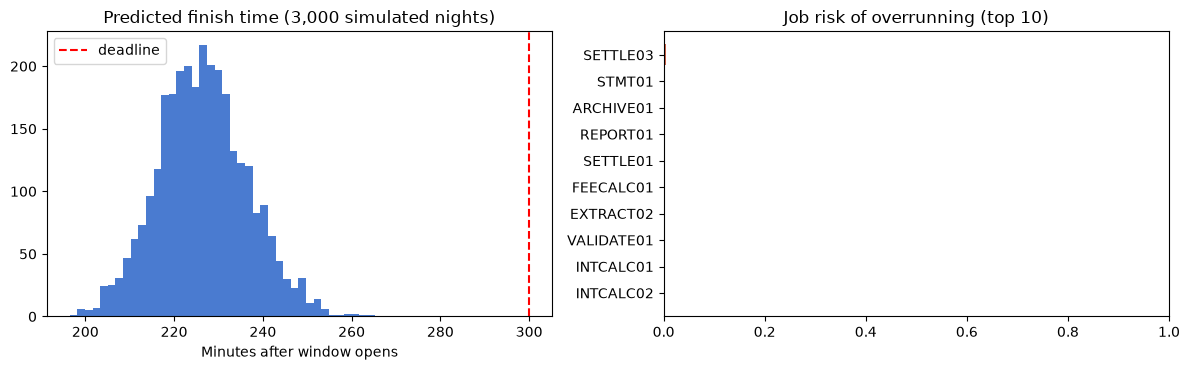

In [9]:
res_a = show("Normal night")

## Step 10. Scenario B: month-end + oversized SETTLE03 input + contention

== Month-end + oversized SETTLE03 input + contention ==
On-time probability : 0%
Critical path       : EXTRACT01 -> VALIDATE01 -> INTCALC01 -> SETTLE01 -> SETTLE03 -> RECON01 -> STMT01 -> ARCHIVE01 (418 min, window = 300 min)
 - SETTLE03 is at 100% risk of overrunning: it is running ~197% slower than usual because its input file is 2.5x larger than usual and CPU time is 35% above normal (system contention).
 - ARCHIVE01 is at 99% risk of overrunning: it is running ~62% slower than usual because CPU time is 35% above normal (system contention).
 - SETTLE01 is at 99% risk of overrunning: it is running ~62% slower than usual because CPU time is 35% above normal (system contention).
 - REPORT01 is at 99% risk of overrunning: it is running ~62% slower than usual because CPU time is 35% above normal (system contention).


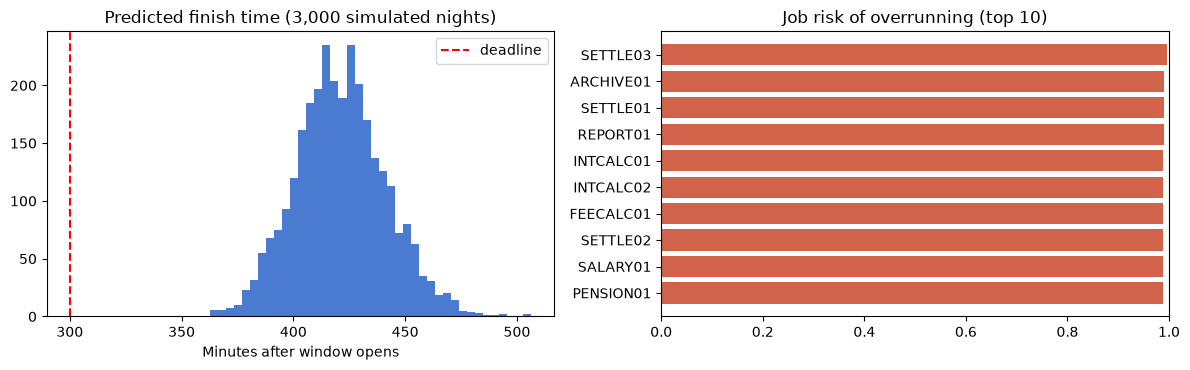

In [10]:
res_b = show("Month-end + oversized SETTLE03 input + contention",
             month_end=True, contention=True, faults={"SETTLE03": 2.0})

## Step 11. Apply the recommended fix and re-forecast

In [11]:
if res_b["rec"]:
    text, job, p_fix = res_b["rec"]
    print(text)
    fixed = dict(res_b["slowdown"]); fixed[job] = 1.0 + (fixed[job] - 1.0) * 0.5
    p2, _, _ = simulate_night(res_b["graph"], fixed)
    print(f"On-time chance: {res_b['p_on_time']:.0%} -> {p2:.0%}  ({p2 - res_b['p_on_time']:+.0%})")
else:
    print("No single fix is enough here: the night is too far gone. Try Step 12 with a milder scenario.")

No single fix is enough here: the night is too far gone. Try Step 12 with a milder scenario.


## Step 12. Try your own scenario
Change the values in the cell below and run it. (Same idea as the dashboard sliders.)

== My scenario ==
On-time probability : 21%
Critical path       : EXTRACT01 -> VALIDATE01 -> INTCALC01 -> SETTLE01 -> SETTLE03 -> RECON01 -> STMT01 -> ARCHIVE01 (310 min, window = 300 min)
 - SETTLE03 is at 99% risk of overrunning: it is running ~120% slower than usual because its input file is 2.5x larger than usual.
ACTION: Give SETTLE03 extra CPU / higher priority now: on-time chance rises from 21% to 82%.


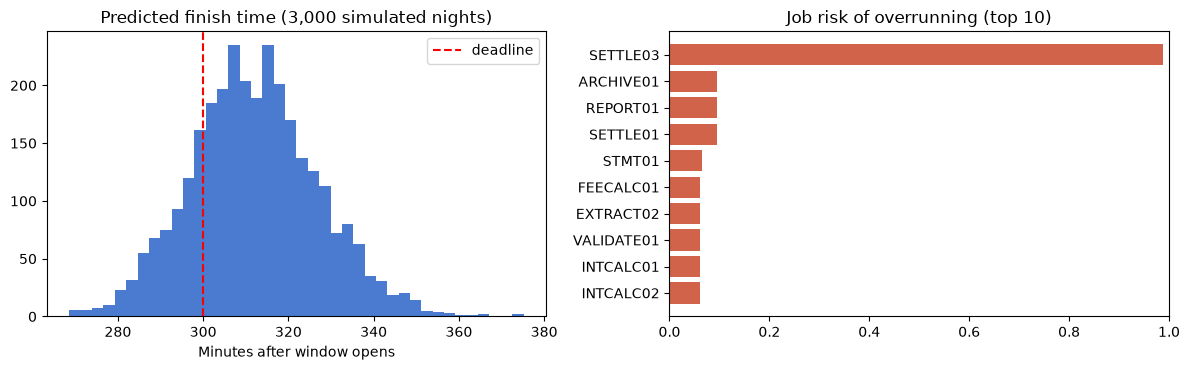

In [12]:
res_c = show("My scenario",
             month_end=True,        # True / False
             festival=False,        # True / False
             contention=False,      # True / False
             faults={"SETTLE03": 2.0})   # job name -> input size multiplier, e.g. {"RECON01": 1.8}

## Optional: interactive sliders
Works if `ipywidgets` is installed in your JupyterLab. If it shows an error or nothing appears, skip it; Step 12 does the same thing.

In [13]:
try:
    import ipywidgets as w
    from IPython.display import display, clear_output
    job_names = [j[0] for j in JOBS]
    me = w.Checkbox(value=True, description="Month-end")
    fe = w.Checkbox(value=False, description="Festival")
    co = w.Checkbox(value=False, description="Contention")
    fj = w.Dropdown(options=["None"] + job_names, value="SETTLE03", description="Big input on")
    fs = w.FloatSlider(value=2.0, min=1.0, max=3.0, step=0.1, description="Size x")
    out = w.Output()
    def _run(_=None):
        with out:
            clear_output(wait=True)
            show("Interactive", month_end=me.value, festival=fe.value, contention=co.value,
                 faults={} if fj.value == "None" else {fj.value: fs.value})
    for x in (me, fe, co, fj, fs): x.observe(_run, names="value")
    display(w.VBox([w.HBox([me, fe, co]), w.HBox([fj, fs]), out])); _run()
except Exception as e:
    print("Interactive widgets not available here:", e)
    print("Use Step 12 instead.")